## Introduction to Quantum Computing: Labs

### Lab 4: Complex Numbers, Rotation Gates and the Bloch Sphere

In this notebook, you will explore complex amplitudes, rotation gates and
the Bloch sphere.

You have already used these helper functions:

- `sv_state(quantum_circuit, label=None)` displays the **quantum state** after the gates have been applied.
- `sv_probs(quantum_circuit, label=None)` displays the **theoretical measurement probabilities** in the computational basis.

Use `label` to add a description to the output. Calculate the state and its
probabilities before adding measurements to the circuit.


In [1]:
import numpy as np
from IPython.display import display
from qiskit import QuantumCircuit
from qc_lecture_tools.statevector import sv_state, sv_probs

### A Brief Mathematical Review: Complex Numbers

A complex number $z=a+ib$ corresponds to the point $(a,b)$ in the complex
plane, where $i^2=-1$.

$$\begin{aligned}
(a+ib)+(c+id)&=(a+c)+i(b+d),\\
(a+ib)(c+id)&=(ac-bd)+i(ad+bc),\\
\overline z&=a-ib,\qquad |z|=\sqrt{a^2+b^2},\qquad |z|^2=z\overline z.
\end{aligned}$$

In **polar form**, $r$ is the magnitude and $\varphi$ is the angle (phase):

$$z=r e^{i\varphi},\qquad e^{i\varphi}=\cos\varphi+i\sin\varphi.$$

Angles are measured in radians: $\pi$ radians correspond to $180^\circ$.


### Exercise 1: Complex Numbers in Python

Python uses `1j` to represent $i$.

| Quantity | Python |
|:--|:--|
| Real and imaginary parts | `z.real`, `z.imag` |
| Complex conjugate | `np.conj(z)` |
| Magnitude / squared magnitude | `abs(z)` / `abs(z)**2` |

Here is an example:


In [2]:
z = 1 + 2j
w = 2 - 1j
print("Real part:", z.real, "Imaginary part:", z.imag)
print("Complex conjugate:", np.conj(z))
print("z + w =", z + w)
print("z * w =", z * w)
print("i² =", (1j)**2)


Real part: 1.0 Imaginary part: 2.0
Complex conjugate: (1-2j)
z + w = (3+1j)
z * w = (4+3j)
i² = (-1+0j)


**Exercise 1.1:** For $z=(1+i)/2$, calculate $z^2$, $|z|^2$
and $\overline z\,z$ by hand and in Python.
What is the difference between the square and the squared magnitude?


In [3]:
z = (1 + 1j) / 2
print("z² =", z**2)
print("|z|² =", abs(z)**2)
print("Conjugate of z times z =", np.conj(z) * z)


z² = 0.5j
|z|² = 0.5000000000000001
Conjugate of z times z = (0.5+0j)


**Observation:** $z^2=i/2$, whereas $|z|^2=\overline z\,z=1/2$.
The squared magnitude is always real and nonnegative.


**Exercise 1.2:** Calculate the measurement probabilities in the
computational basis and check the normalization of

$$|\psi\rangle=\frac{1+i}{2}|0\rangle+\frac{1-i}{2}|1\rangle.$$

Why do we use squared magnitudes rather than ordinary squares?


In [4]:
alpha = (1 + 1j) / 2
beta = (1 - 1j) / 2
p0 = abs(alpha)**2
p1 = abs(beta)**2
print("p(0) =", p0, "p(1) =", p1)
print("Sum =", p0 + p1)


p(0) = 0.5000000000000001 p(1) = 0.5000000000000001
Sum = 1.0000000000000002


**Observation:** $p(0)=p(1)=1/2$, so the probabilities sum to 1.
The ordinary squares would be $\pm i/2$, which cannot be probabilities.


### Exercise 2: Polar Form and Rotations

Polar form expresses a complex number in terms of its magnitude and angle:

$$z=r e^{i\varphi}=r(\cos\varphi+i\sin\varphi),\qquad r=|z|.$$

The angle is called the **argument** or **phase**. Python's functions
`np.angle` and `np.exp` use radians. A full turn corresponds to $2\pi$ radians:
$\pi/3$ radians correspond to $60^\circ$, $\pi/2$ to $90^\circ$,
$\pi$ to $180^\circ$ and $2\pi$ to $360^\circ$.

When multiplying complex numbers, **multiply their magnitudes and add their phases**:

$$
(r_1e^{i\varphi_1})(r_2e^{i\varphi_2})
=r_1r_2e^{i(\varphi_1+\varphi_2)}.
$$

A factor $e^{i\varphi}$ has magnitude 1, so it only rotates the arrow
representing the complex number in the complex plane.

| Conversion | Python |
|:--|:--|
| Magnitude | `abs(z)` |
| Phase | `np.angle(z)` |
| Reconstruct the number from polar form | `r * np.exp(1j * phi)` |

`np.angle` returns the principal phase between $-\pi$ and $\pi$.
Angles that differ by an integer multiple of $2\pi$ represent the same direction.

**Exercise 2.1:** Calculate the magnitude and phase of $1+i$, $-1+i$ and
$-1-i$ in Python. Print the phases as multiples of $\pi$ using `phi / np.pi`
and reconstruct the numbers from their polar form.
Repeat the same calculation for each value.


In [5]:
z = 1 + 1j
r = abs(z)
phi = np.angle(z)
print("Number:", z)
print("Magnitude:", r)
print("Phase / pi:", phi / np.pi)
print("Reconstructed:", r * np.exp(1j * phi))


Number: (1+1j)
Magnitude: 1.4142135623730951
Phase / pi: 0.25
Reconstructed: (1.0000000000000002+1j)


In [6]:
z = -1 + 1j
r = abs(z)
phi = np.angle(z)
print("Number:", z)
print("Magnitude:", r)
print("Phase / pi:", phi / np.pi)
print("Reconstructed:", r * np.exp(1j * phi))


Number: (-1+1j)
Magnitude: 1.4142135623730951
Phase / pi: 0.75
Reconstructed: (-1+1.0000000000000002j)


In [7]:
z = -1 - 1j
r = abs(z)
phi = np.angle(z)
print("Number:", z)
print("Magnitude:", r)
print("Phase / pi:", phi / np.pi)
print("Reconstructed:", r * np.exp(1j * phi))


Number: (-1-1j)
Magnitude: 1.4142135623730951
Phase / pi: -0.75
Reconstructed: (-1-1.0000000000000002j)


**Exercise 2.2:** Why do $e^{-3i\pi/4}$ and $e^{5i\pi/4}$ represent
the same number? You can check this in Python. Also examine the value of $e^{2\pi i}$.


**Observation:** The angles differ by $2\pi$, and $e^{2\pi i}=1$:

$$e^{5i\pi/4}=e^{-3i\pi/4}e^{2i\pi}=e^{-3i\pi/4}.$$


**Exercise 2.3:** In quantum computing, we often use phase factors
$e^{ia}$ with magnitude 1. In Python, multiply $z=(1+i)/2$ by
$e^{ia}$ for $a=\pi/2,\pi,\pi/4$.

Compare the magnitude and phase of $z$ before and after the multiplication.
What changes? Explain your answer using polar form.


In [8]:
z = (1 + 1j) / 2
a = np.pi / 2  # also try np.pi and np.pi / 4
phase_factor = np.exp(1j * a)
z_rotated = z * phase_factor
print("Phase factor:", phase_factor, "Magnitude:", abs(phase_factor))
print("Result:", z_rotated)
print("Magnitudes:", abs(z), abs(z_rotated))
print("Phases / pi:", np.angle(z) / np.pi, np.angle(z_rotated) / np.pi)


Phase factor: (6.123233995736766e-17+1j) Magnitude: 1.0
Result: (-0.49999999999999994+0.5j)
Magnitudes: 0.7071067811865476 0.7071067811865475
Phases / pi: 0.25 0.75


**Observation:** The three phase factors give the following results:

| $a$ | Result | Principal phase |
|:--|:--|:--|
| $\pi/2$ | $(-1+i)/2$ | $3\pi/4$ |
| $\pi$ | $(-1-i)/2$ | $-3\pi/4$ |
| $\pi/4$ | $i/\sqrt2$ | $\pi/2$ |

$$r e^{i\varphi}e^{ia}=r e^{i(\varphi+a)}.$$

**The phases add, while the magnitude stays the same**, here $1/\sqrt2$.
The resulting phase can be reduced modulo $2\pi$ to the principal range.


### Exercise 3: Rotation Gates and the Bloch Sphere

A pure single-qubit state corresponds to a point on the surface of the Bloch sphere.
Up to a global phase, it can be written as

$$|\psi\rangle=\cos(\theta/2)|0\rangle
+e^{i\varphi}\sin(\theta/2)|1\rangle,
\qquad 0\le\theta\le\pi,\quad 0\le\varphi<2\pi.$$

A common factor $e^{i\gamma}$ multiplying all amplitudes is an unobservable
**global phase**. If the first amplitude is nonzero, we can factor out its
phase and choose that amplitude to be real and nonnegative.

$\theta$ is the polar angle measured from the north pole, and $\varphi$ is
the azimuthal angle around the $z$-axis. Away from the poles, $\varphi$ is
also the **relative phase** between the two amplitudes.
$|0\rangle$ is at the north pole, and $|1\rangle$ is at the south pole.
On the equator, the measurement probabilities in the computational basis are
$p(0)=p(1)=1/2$.

Rotation gates rotate the Bloch vector about the corresponding axis:

| Gate | Qiskit |
|:--|:--|
| $R_x(\lambda)$ | `quantum_circuit.rx(angle, 0)` |
| $R_y(\lambda)$ | `quantum_circuit.ry(angle, 0)` |
| $R_z(\lambda)$ | `quantum_circuit.rz(angle, 0)` |

Here, `angle` is the rotation angle $\lambda$, measured in radians.


The helper function `sv_interactive_blochsphere` displays the state
prepared by a single-qubit circuit on the Bloch sphere.

In Qiskit, rotation gates can also use free parameters.
For example, `Parameter("angle")` is a placeholder for an angle.
`sv_interactive_blochsphere` then displays the Bloch sphere with sliders
for the parameters. The slider values are multiples of $\pi$:
a value of `0.5` represents $\pi/2$ radians.

For fixed angles, use `sv_state` and `sv_probs` as before.

**Example: $R_y$ and $R_z$ with two adjustable angles.**


In [9]:
from qc_lecture_tools.statevector import sv_interactive_blochsphere
from qiskit.circuit import Parameter

angle1 = Parameter("angle 1")
angle2 = Parameter("angle 2")
quantum_circuit = QuantumCircuit(1)
quantum_circuit.ry(angle1, 0)
quantum_circuit.rz(angle2, 0)
display(sv_interactive_blochsphere(quantum_circuit))


**Exercise 3.1:** Create a circuit with a Hadamard gate followed by
a parameterized $R_z$ gate. Use the Bloch sphere slider to select the angles
$0$, $\pi/2$ and $\pi$.

Also create circuits with the fixed angles $0$, $\pi/2$ and $\pi$.
For each circuit, display the state and the measurement probabilities
using `sv_state` and `sv_probs`.
What changes about the Bloch vector? What happens to the measurement
probabilities in the computational basis?


In [10]:
qc_rz_interactive = QuantumCircuit(1)
qc_rz_interactive.h(0)
qc_rz_interactive.rz(angle1, 0)
display(sv_interactive_blochsphere(qc_rz_interactive))


In [11]:
phi = np.pi / 2  # also try 0 and np.pi
qc_rz = QuantumCircuit(1)
qc_rz.h(0)
qc_rz.rz(phi, 0)
display(sv_state(qc_rz))
display(sv_probs(qc_rz))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Exercise 3.2:** Repeat the experiment using only an $R_x$ gate,
then using only an $R_y$ gate. In each case, start from $|0\rangle$
without applying a Hadamard gate. Test the angles $0$, $\pi/2$ and $\pi$
with the slider, and calculate the states and their measurement probabilities
for the corresponding fixed angles.

Which rotation produces a purely imaginary second amplitude at $\pi/2$?
Do the states represent the same physical state even though their measurement
probabilities in the computational basis are identical?


In [12]:
qc_rx_interactive = QuantumCircuit(1)
qc_rx_interactive.rx(angle1, 0)
display(sv_interactive_blochsphere(qc_rx_interactive))


In [13]:
qc_ry_interactive = QuantumCircuit(1)
qc_ry_interactive.ry(angle1, 0)
display(sv_interactive_blochsphere(qc_ry_interactive))


In [14]:
a = np.pi / 2  # also try 0 and np.pi
qc_rx = QuantumCircuit(1)
qc_rx.rx(a, 0)
display(sv_state(qc_rx, "Rx: "))
display(sv_probs(qc_rx))

qc_ry = QuantumCircuit(1)
qc_ry.ry(a, 0)
display(sv_state(qc_ry, "Ry: "))
display(sv_probs(qc_ry))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Observation:** Applying the rotation gates to $|0\rangle$ gives:

| Angle | $R_x$ applied to $\lvert0\rangle$ | $R_y$ applied to $\lvert0\rangle$ |
|:--|:--|:--|
| $0$ | $\lvert0\rangle$ | $\lvert0\rangle$ |
| $\pi/2$ | $(\lvert0\rangle-i\lvert1\rangle)/\sqrt2$ | $(\lvert0\rangle+\lvert1\rangle)/\sqrt2$ |
| $\pi$ | $-i\lvert1\rangle$ | $\lvert1\rangle$ |

At $\pi/2$, the states are physically different: their relative phases differ.
Nevertheless, both give $p(0)=p(1)=1/2$ when measured in the computational basis.


**Exercise 3.3:** Match the following states to the directions
$+z,-z,+x,-x,+y,-y$ and give suitable angles $\theta,\varphi$:

$$\begin{gathered}
|0\rangle,\quad |1\rangle,\\
\frac{1}{\sqrt2}|0\rangle+\frac{1}{\sqrt2}|1\rangle,\quad
\frac{1}{\sqrt2}|0\rangle-\frac{1}{\sqrt2}|1\rangle,\\
\frac{1}{\sqrt2}|0\rangle+\frac{i}{\sqrt2}|1\rangle,\quad
\frac{1}{\sqrt2}|0\rangle-\frac{i}{\sqrt2}|1\rangle.
\end{gathered}$$

Where do states that can be represented with real amplitudes, up to a global
phase, lie on the Bloch sphere? Why is $\varphi$ arbitrary at the poles?

If needed, check your angles using a circuit with $R_y$ followed by $R_z$.
The prepared states may differ from the listed states by a global phase.


**Observation:** The states correspond to the following directions:

| State | $\theta$ | $\varphi$ | Direction |
|:--|:--|:--|:--|
| $\lvert0\rangle$ | $0$ | arbitrary | $+z$ |
| $\lvert1\rangle$ | $\pi$ | arbitrary | $-z$ |
| $\frac{1}{\sqrt2}\lvert0\rangle+\frac{1}{\sqrt2}\lvert1\rangle$ | $\pi/2$ | $0$ | $+x$ |
| $\frac{1}{\sqrt2}\lvert0\rangle-\frac{1}{\sqrt2}\lvert1\rangle$ | $\pi/2$ | $\pi$ | $-x$ |
| $\frac{1}{\sqrt2}\lvert0\rangle+\frac{i}{\sqrt2}\lvert1\rangle$ | $\pi/2$ | $\pi/2$ | $+y$ |
| $\frac{1}{\sqrt2}\lvert0\rangle-\frac{i}{\sqrt2}\lvert1\rangle$ | $\pi/2$ | $3\pi/2$ | $-y$ |

States that can be represented with real amplitudes, up to a global phase,
lie on the great circle in the $x$-$z$ plane.
At either pole, one amplitude vanishes, so the phase of the remaining
amplitude is only a global phase.


**Exercise 3.4:** Starting from $|0\rangle$, apply $R_y$ followed
by $R_z$ to prepare the state

$$|\psi\rangle=\frac{\sqrt3 i}{2}|0\rangle+\frac{i}{2}|1\rangle$$

up to a global phase. Try simple rotation angles such as $0$ and $\pm\pi/n$
for positive integers $n$.

Display the state and its measurement probabilities.
Then change only the $R_z$ rotation angle.
What changes on the Bloch sphere? What happens to the measurement
probabilities in the computational basis?


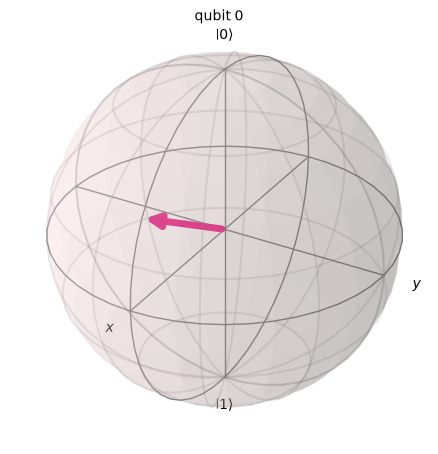

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [15]:
theta = -np.pi / 3
phi = -np.pi 
qc_target = QuantumCircuit(1)
qc_target.ry(theta, 0)
qc_target.rz(phi, 0)
display(sv_interactive_blochsphere(qc_target))
display(sv_state(qc_target))
display(sv_probs(qc_target))


**Observation:** The rotation angles used above prepare the target
state exactly. They are gate rotation angles; the Bloch sphere coordinates
of the resulting state are $\theta=\pi/3$ and $\varphi=0$.

Changing only the $R_z$ rotation angle moves the tip of the Bloch vector
along a circle of constant latitude. The measurement probabilities in the
computational basis remain $p(0)=3/4$ and $p(1)=1/4$.


### Exercise 4: Circuits for States with Complex Amplitudes

For each state below, find a circuit that prepares it from $|0\rangle$.
Use only single-qubit gates. Your result may differ from the target state
by a global phase.

For each circuit, display the state and its measurement probabilities in
the computational basis using `sv_state` and `sv_probs`.


**Exercise 4.1:**

$$|\psi_1\rangle=\frac{1}{\sqrt2}|0\rangle+\frac{1+i}{2}|1\rangle.$$


In [16]:
qc_target_1 = QuantumCircuit(1)
qc_target_1.h(0)
qc_target_1.t(0)
display(sv_state(qc_target_1))
display(sv_probs(qc_target_1))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Exercise 4.2:**

$$|\psi_2\rangle=\frac{\sqrt3}{2}|0\rangle-\frac{i}{2}|1\rangle.$$


In [17]:
qc_target_2 = QuantumCircuit(1)
qc_target_2.rx(np.pi / 3, 0)
display(sv_state(qc_target_2))
display(sv_probs(qc_target_2))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Exercise 4.3:**

$$|\psi_3\rangle=\frac{1+i}{2}|0\rangle+\frac{1-i}{2}|1\rangle.$$


In [18]:
qc_target_3 = QuantumCircuit(1)
qc_target_3.ry(np.pi / 2, 0)
qc_target_3.rz(-np.pi / 2, 0)
display(sv_state(qc_target_3))
display(sv_probs(qc_target_3))


<IPython.core.display.Math object>

<IPython.core.display.Math object>